# Random Forest Classification and Feature Importance

## Project Introduction

The goal of this project is to classify breast tumors as **malignant (target 0)** or **benign (target 1)** using the Breast Cancer Wisconsin dataset and a Random Forest classifier.

The notebook explores the dataset, splits it into training and test sets, compares model hyperparameters with cross-validation, evaluates classification performance, and interprets feature importance. Because this is a medical classification example, malignant-class recall and false negatives are important alongside overall accuracy.

The results are for educational analysis only and should not be used as a clinical diagnostic tool.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score , GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score
)


## 1. Import Libraries

The libraries used in this notebook support data handling (`pandas`), plotting (`matplotlib`), model training (`RandomForestClassifier`), model selection (`GridSearchCV`, `StratifiedKFold`, and `cross_val_score`), and evaluation (`accuracy_score`, `recall_score`, the classification report, confusion matrix, and permutation importance).

Using separate tools for training, validation, evaluation, and interpretation helps us assess both predictive performance and which features the fitted model relies on.

In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data , columns=data.feature_names)
y = pd.Series(data.target , name="target")

X.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
X.tail()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039


In [4]:
y.head(10)

0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
8    0
9    0
Name: target, dtype: int64

In [5]:
y.tail(10)

559    1
560    1
561    1
562    0
563    0
564    0
565    0
566    0
567    0
568    1
Name: target, dtype: int64

In [6]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [7]:
X.shape

(569, 30)

In [8]:
y.value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [9]:
X.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

## 2. Load and Explore the Dataset

The Breast Cancer Wisconsin dataset contains measurements of cell nuclei and a binary target. In this dataset, **target 0 is malignant** and **target 1 is benign**.

The exploration cells inspect the feature names and data types, dataset dimensions, target distribution, and missing values. These checks help confirm what the model will learn from and whether any basic data-quality issues need attention.

The training split contains 455 samples: 170 malignant cases (class 0) and 285 benign cases (class 1). This means benign cases are more frequent in the training data, so class distribution should be considered when evaluating the model.

In [10]:
X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## 3. Splitting the Dataset

We split the dataset into training and testing sets so that final evaluation uses examples that were not used to fit the model or select its hyperparameters.

- **X_train / y_train:** Features and target labels used for model fitting and cross-validation.
- **X_test / y_test:** Held-out features and labels used for final evaluation.
- **test_size=0.2:** Assigns 20% of the 569 samples (114 samples) to the test set and 80% to training.
- **random_state=42:** Makes the split reproducible.
- **stratify=y:** Preserves the class proportions as closely as possible in both sets.

Cross-validation is performed on the training set. The held-out test set should be used for the final assessment, not repeatedly used to choose hyperparameters.

In [11]:
model = RandomForestClassifier(random_state=42 ,
                               class_weight="balanced")

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grd = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=cv,
    scoring="recall_macro",
    n_jobs=-1,
    verbose=1,
    return_train_score=True

)

grd.fit(X_train, y_train)

print("Best Parameters:")
print(grd.best_params_)

print("Best CV Score:")
print(grd.best_score_)

best_rf = grd.best_estimator_




Fitting 5 folds for each of 216 candidates, totalling 1080 fits


Best Parameters:
{'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best CV Score:
0.9659958720330236


## 4. Building and Training the Random Forest Model

Random Forest combines predictions from many decision trees. Each tree is trained using randomized samples/features, and the ensemble can provide more stable predictions than a single tree.

### Hyperparameters and model selection

The initial model object is supplied to `GridSearchCV`, which evaluates candidate parameter combinations. The grid searches over:

- **`n_estimators`**: number of trees (100, 200, or 300).
- **`max_depth`**: maximum tree depth (5, 10, 15, or unlimited with `None`).
- **`min_samples_split`**: minimum number of samples required to split a node.
- **`min_samples_leaf`**: minimum number of samples allowed in a leaf.
- **`max_features`**: number/type of features considered at each split (`sqrt` or `log2`).
- **`class_weight="balanced"`**: adjusts class weights inversely according to their frequencies in the training data.

The saved GridSearchCV output selects `n_estimators=300`, `max_depth=5`, `max_features='log2'`, `min_samples_leaf=1`, and `min_samples_split=2`, with a best mean five-fold `recall_macro` score of approximately **0.9660**. This is the result for the scoring metric used by GridSearchCV; it should not be confused with accuracy.

Random Forest does not require `StandardScaler` because tree splits are based on feature thresholds and are not sensitive to feature scale. The current model workflow should therefore be described without claiming that scaling is retained.

## 5. Hyperparameter Comparison and Cross-Validation

A single train/test split gives only one estimate of performance. The test set has 114 samples, so this notebook also uses **five-fold stratified cross-validation** on the training set. Stratification aims to preserve the class proportions in each fold.

Two comparisons are shown in the notebook and their scoring metrics differ:

- **GridSearchCV table:** evaluates parameter combinations using `recall_macro`, the average recall across the two classes. The saved best score is approximately **0.9660**.
- **Manual cross-validation table:** compares selected `n_estimators` and `max_depth` values using **accuracy**, and also displays the training accuracy, test accuracy, and malignant-class recall.

In the saved manual comparison, the highest displayed mean CV accuracy is **0.9604** for several settings, including `max_depth=10` and `max_depth=None`; the displayed test accuracy for those rows is **0.9474** and malignant recall is **0.9524**. A deeper tree is not automatically better: compare validation performance and the gap between training and validation/test scores.

The saved GridSearchCV choice and the manual accuracy table use different scoring metrics, so their scores should not be compared as if they were the same measure. The final model choice should be justified using the chosen selection metric and the medical priority of detecting malignant cases.

The training counts are 170 malignant cases (class 0) and 285 benign cases (class 1). `class_weight="balanced"` gives relatively more weight to the less frequent malignant class. This is a reasonable option to evaluate, but its benefit should be judged by malignant recall and other validation results rather than assumed.

In [12]:
y_train_pred = best_rf.predict(X_train)
y_prec = best_rf.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_prec)

print("Training Accuracy =", train_acc)
print("Test Accuracy =", test_acc)

print("\\nTraining class counts:")
print(y_train.value_counts().sort_index())

print("\\nClassification Report:")
print(classification_report(
    y_test,
    y_prec,
    target_names=data.target_names
))

print("Confusion Matrix (rows = true labels, columns = predicted labels):")
print(confusion_matrix(y_test, y_prec, labels=[0, 1]))

Training Accuracy = 0.9978021978021978
Test Accuracy = 0.9385964912280702
\nTraining class counts:
target
0    170
1    285
Name: count, dtype: int64
\nClassification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114

Confusion Matrix (rows = true labels, columns = predicted labels):
[[39  3]
 [ 4 68]]


In [13]:


results = pd.DataFrame(grd.cv_results_)

results = results[
    [
        "param_n_estimators",
        "param_max_depth",
        "param_min_samples_split",
        "param_min_samples_leaf",
        "param_max_features",
        "mean_test_score",
        "std_test_score",
        "mean_train_score"
    ]
]

results = results.sort_values(
    by="mean_test_score",
    ascending=False
)

results.head(10)


,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_max_features,mean_test_score,std_test_score,mean_train_score
38,300,5,2,2,log2,0.965996,0.018600,0.992067
37,200,5,2,2,log2,0.965996,0.018600,0.992067
83,300,10,2,1,log2,0.965996,0.018600,1.000000
82,200,10,2,1,log2,0.965996,0.015581,1.000000
29,300,5,2,1,log2,0.965996,0.018600,0.997059
31,200,5,5,1,log2,0.965996,0.018600,0.993537
137,300,15,2,1,log2,0.965996,0.018600,1.000000
136,200,15,2,1,log2,0.965996,0.015581,1.000000
191,300,None,2,1,log2,0.965996,0.018600,1.000000
190,200,None,2,1,log2,0.965996,0.015581,1.000000


In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for n in [100, 200, 300]:
    for depth in [5, 10, None]:
        candidate = RandomForestClassifier(
            n_estimators=n,
            max_depth=depth,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        )

        scores = cross_val_score(
            candidate,
            X_train,
            y_train,
            cv=cv,
            scoring="accuracy",
            n_jobs=-1
        )

        candidate.fit(X_train, y_train)
        train_score = accuracy_score(y_train, candidate.predict(X_train))
        test_score = accuracy_score(y_test, candidate.predict(X_test))
        malignant_recall = recall_score(
            y_test,
            candidate.predict(X_test),
            pos_label=0
        )

        cv_results.append({
            "n_estimators": n,
            "max_depth": depth,
            "CV Accuracy (mean)": scores.mean(),
            "CV Accuracy (std)": scores.std(),
            "Train Accuracy": train_score,
            "Test Accuracy": test_score,
            "Malignant Recall": malignant_recall
        })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df = cv_results_df.sort_values(
    by="CV Accuracy (mean)",
    ascending=False
)

print(cv_results_df.round(4).to_string(index=False))


 n_estimators  max_depth  CV Accuracy (mean)  CV Accuracy (std)  Train Accuracy  Test Accuracy  Malignant Recall
          100       10.0              0.9604             0.0112          1.0000         0.9474            0.9524
          200       10.0              0.9604             0.0149          1.0000         0.9474            0.9524
          100        NaN              0.9604             0.0112          1.0000         0.9474            0.9524
          200        NaN              0.9604             0.0149          1.0000         0.9474            0.9524
          100        5.0              0.9582             0.0189          0.9978         0.9474            0.9524
          200        5.0              0.9582             0.0189          0.9978         0.9386            0.9286
          300        5.0              0.9560             0.0184          0.9978         0.9386            0.9286
          300       10.0              0.9538             0.0146          1.0000         0.9386  

In [16]:
importance = pd.DataFrame({
    "Feature" : X.columns,
    "importance" : best_rf.feature_importances_

})

importance = importance.sort_values(
    by ="importance",
    ascending=False

)
print(importance.head(10))

                 Feature  importance
22       worst perimeter    0.130695
23            worst area    0.125992
7    mean concave points    0.091517
27  worst concave points    0.090087
20          worst radius    0.079386
6         mean concavity    0.060812
2         mean perimeter    0.057548
0            mean radius    0.050428
3              mean area    0.047972
26       worst concavity    0.042277


## 5. Feature Importance Analysis

The feature-importance table ranks input features using `model.feature_importances_`, the Random Forest's impurity-based importance measure.

- **`model.feature_importances_`:** reports how much each feature contributed to impurity reduction across the fitted trees.
- **`X.columns`:** supplies the feature names.
- **`pd.DataFrame()`:** combines feature names and importance values.
- **`sort_values(..., ascending=False)`:** orders features from highest to lowest importance.
- **`head(10)`:** displays the ten highest-ranked features.

In the saved table, the highest scores are `worst perimeter` (0.1520), `worst area` (0.1188), `worst concave points` (0.1120), `mean concave points` (0.1064), and `worst radius` (0.0713).

A larger impurity-based score means a feature contributed more to the forest's splits under this importance measure. It does **not** prove that the feature causes malignancy or that its score equals a percentage of predictive accuracy. Correlated features can share or redistribute importance, so the ranking should be interpreted together with permutation importance.

**Output note:** the code currently calculates this table from the variable named `model`, while GridSearchCV's selected estimator is stored in `best_rf`. The saved output should not be described as the selected model's feature importance unless the estimator used for this calculation is verified.

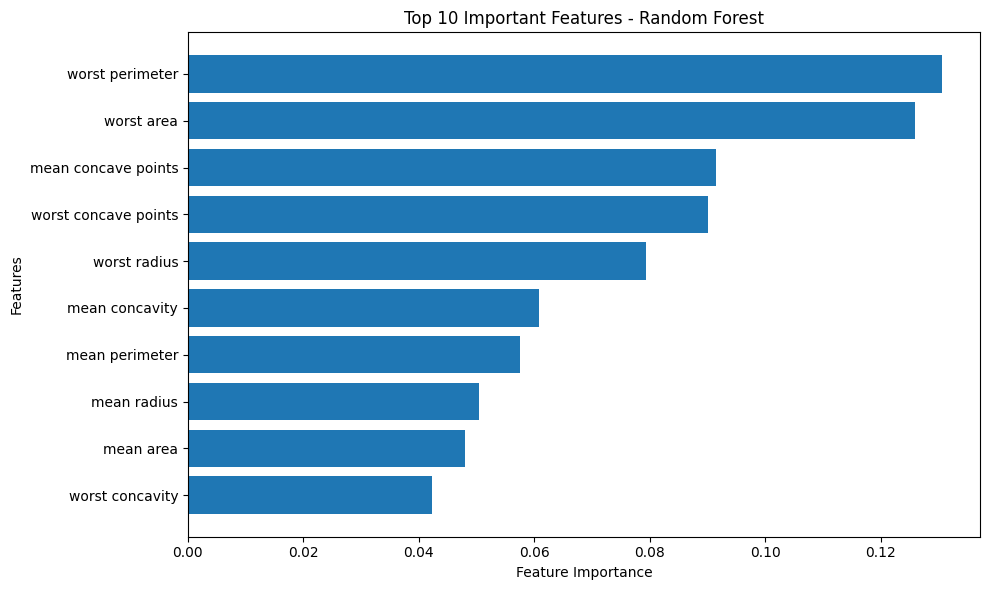

In [17]:
top_features = importance.head(10).sort_values(by="importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features - Random Forest")
plt.tight_layout()
plt.show()


## 6. Visualizing Feature Importance

The horizontal bar chart displays the ten highest feature-importance scores from the table above.

- **`top_features`:** selects the ten highest-ranked features and sorts them for display.
- **`plt.barh()`:** draws a horizontal bar for each feature.
- **Axis labels and title:** identify the feature names and importance scores.
- **`tight_layout()` and `show()`:** improve spacing and display the figure.

Longer bars represent larger impurity-based importance scores. The chart helps compare the relative scores, but it does not establish causation and can be affected by correlations among features.

## 7. Interpreting Feature Importance, Correlation, and Permutation Importance

### What the highest-ranked features represent

In the saved impurity-importance table, the leading features are `worst perimeter` (0.1520), `worst area` (0.1188), `worst concave points` (0.1120), `mean concave points` (0.1064), and `worst radius` (0.0713). Perimeter, area, and radius describe related aspects of cell-nucleus size; concave-point and concavity measurements describe aspects of the nucleus boundary and shape.

### Why radius, perimeter, and area can cluster together

Radius, perimeter, and area are related measurements of nucleus size, so they tend to be correlated and can carry overlapping information. When correlated features are available together, a Random Forest may use one feature for a split instead of another similar feature. Their individual importance scores can therefore be divided across the group, and one feature may rank lower even when the group is informative.

### Comparing the two importance methods

`feature_importances_` measures impurity reduction accumulated across the fitted trees. `permutation_importance`, by contrast, shuffles one feature at a time in the held-out test set and measures the resulting change in the chosen score—in this notebook, accuracy. A larger positive decrease means the model's test accuracy relies more on that feature under this permutation test.

In the saved permutation output, `mean concave points` has the largest displayed mean decrease in test accuracy (0.006579), followed by `worst texture` (0.005702) and `mean compactness` (0.005263). This differs from the impurity ranking, where `worst perimeter` ranks first. Such differences are possible because the methods measure different things, and correlated features may substitute for one another. The reported permutation standard deviations also matter: small mean changes with relatively large variation should be interpreted cautiously.

**Important limitation:** the current code calculates both importance methods using the variable `model`, rather than explicitly using `best_rf`. Therefore, these saved tables describe the outputs currently present in the notebook; do not claim they are definitely the selected GridSearchCV model's importances until the estimator reference is verified. Neither importance method demonstrates causation or provides a medical diagnosis.

            Feature  importance  Permutation Importance Mean  Permutation Importance Std
       mean texture    0.012273                     0.003947                    0.005171
      worst texture    0.021330                     0.001754                    0.009448
   worst smoothness    0.014799                     0.001754                    0.005949
mean concave points    0.091517                     0.001316                    0.006371
          mean area    0.047972                     0.001316                    0.003132
       radius error    0.016675                     0.001316                    0.003132
         area error    0.041928                     0.000877                    0.003824
        mean radius    0.050428                     0.000877                    0.002632
   mean compactness    0.018363                     0.000000                    0.000000
     worst symmetry    0.011799                     0.000000                    0.000000


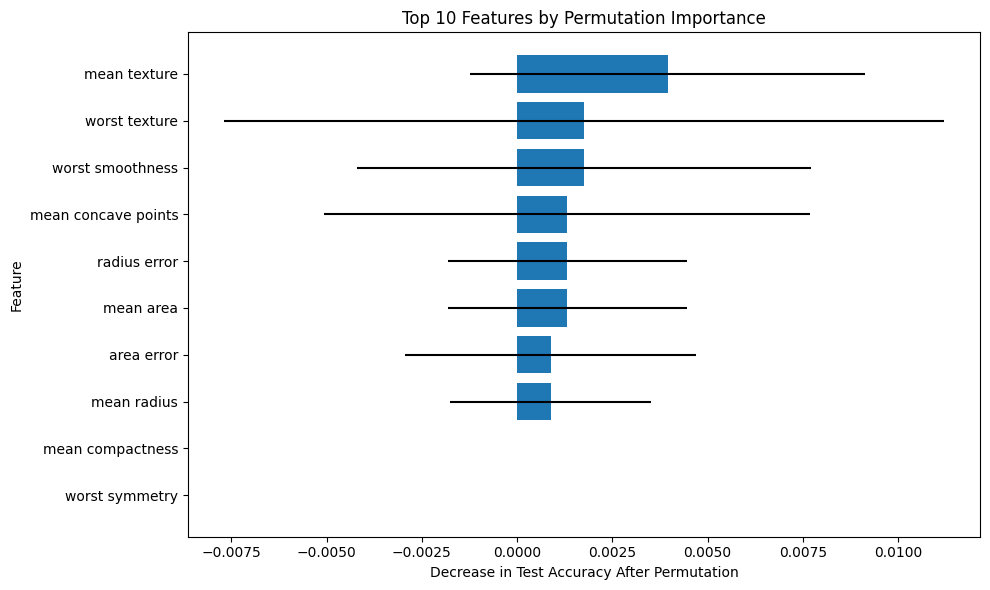

In [19]:
perm = permutation_importance(
    best_rf,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="accuracy"
)

permutation_scores = pd.DataFrame({
    "Feature": X.columns,
    "Permutation Importance Mean": perm.importances_mean,
    "Permutation Importance Std": perm.importances_std
}).sort_values(
    by="Permutation Importance Mean",
    ascending=False
)

importance_comparison = importance.merge(
    permutation_scores,
    on="Feature",
    how="left"
).sort_values(
    by="Permutation Importance Mean",
    ascending=False
)

print(importance_comparison.head(10).to_string(index=False))

top_perm = importance_comparison.head(10).sort_values(
    by="Permutation Importance Mean"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_perm["Feature"],
    top_perm["Permutation Importance Mean"],
    xerr=top_perm["Permutation Importance Std"]
)
plt.xlabel("Decrease in Test Accuracy After Permutation")
plt.ylabel("Feature")
plt.title("Top 10 Features by Permutation Importance")
plt.tight_layout()
plt.show()


## 8. Confusion Matrix and Malignant-Class Recall

The confusion matrix uses rows for true labels and columns for predicted labels, ordered as class 0 (malignant) and class 1 (benign). The upper-right cell therefore counts **false negatives**: malignant cases incorrectly predicted as benign. These are especially costly errors in a medical setting because a malignant case is missed.

The saved confusion matrix printed in the evaluation cell is:

- 39 malignant cases correctly predicted as malignant.
- **3 malignant cases predicted as benign** (false negatives).
- 4 benign cases predicted as malignant (false positives).
- 68 benign cases correctly predicted as benign.

For this matrix, malignant-class recall is 39 / (39 + 3) = **0.9286**. However, another saved output in the notebook reports malignant recall as **0.9524**, which corresponds to a different number of false negatives. The saved outputs are therefore inconsistent and must be refreshed together before the final result is reported.

Recall for class 0 is the key metric to monitor because it measures the proportion of actual malignant cases correctly identified. Overall accuracy alone can hide missed malignant cases. This model is an educational exercise, not a clinically validated diagnostic system.

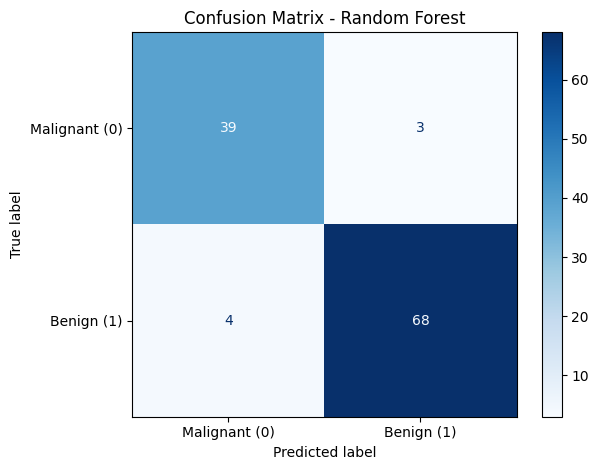

Malignant-class recall = 0.9286


In [20]:
cm = confusion_matrix(y_test, y_prec, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant (0)", "Benign (1)"]
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

malignant_recall = recall_score(y_test, y_prec, pos_label=0)
print("Malignant-class recall =", round(malignant_recall, 4))


## 9. Conclusion

This notebook uses a Random Forest classifier to distinguish malignant (target 0) from benign (target 1) cases in the Breast Cancer Wisconsin dataset. The workflow includes a stratified train/test split, hyperparameter comparison with five-fold cross-validation, a confusion matrix, and two complementary feature-importance methods.

The saved GridSearchCV output selects `n_estimators=300`, `max_depth=5`, `max_features='log2'`, `min_samples_leaf=1`, and `min_samples_split=2`, with a mean five-fold `recall_macro` score of approximately **0.9660**. In the separate manual comparison, the highest displayed mean CV accuracy is **0.9604** for multiple parameter settings. Because these tables use different scoring metrics, their scores should not be treated as directly comparable. The evidence does not establish that `max_depth=10` is uniquely best; the CV results and train/validation gap should guide the choice.

The saved impurity-based importance table ranks `worst perimeter`, `worst area`, and `worst concave points` highest, while the saved permutation-importance table ranks `mean concave points` highest by mean decrease in test accuracy. This difference is plausible because the methods measure different kinds of importance and correlated features can substitute for one another.

The saved evaluation outputs currently conflict: the printed confusion matrix shows three malignant cases predicted as benign, implying malignant recall of 0.9286, while another output reports 0.9524. The notebook's outputs must be refreshed consistently before presenting a definitive final recall value. In a medical setting, malignant-class recall is especially important because false negatives are costly. This model is an educational experiment and is not a clinically validated diagnostic system.